In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import Precision, Recall


train_dir = "/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
valid_dir = "/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32


train_ds = image_dataset_from_directory(
    train_dir,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = image_dataset_from_directory(
    valid_dir,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Num Classes:", NUM_CLASSES)


Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tom

In [ ]:

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)


In [ ]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15)
])


base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224,224,3)
)
base_model.trainable = False


inputs = tf.keras.Input(shape=(224,224,3))
x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)
model.summary()


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_14 (Sequential)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:

precision = Precision()
recall = Recall()

def f1_score(y_true, y_pred):
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    return 2 * ((p * r) / (p + r + 1e-7))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy", f1_score]
)


In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.3)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


Epoch 1/20


E0000 00:00:1767090365.935053      88 meta_optimizer.cc:966] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_11_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 211s 91ms/step - accuracy: 0.3808 - f1_score: 0.0265 - loss: 2.6159 - val_accuracy: 0.8311 - val_f1_score: 0.3145 - val_loss: 0.9651 - learning_rate: 1.0000e-04
Epoch 2/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 199s 91ms/step - accuracy: 0.8161 - f1_score: 0.3948 - loss: 0.9322 - val_accuracy: 0.8799 - val_f1_score: 0.5464 - val_loss: 0.5842 - learning_rate: 1.0000e-04
Epoch 3/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 198s 90ms/step - accuracy: 0.8600 - f1_score: 0.5838 - loss: 0.6250 - val_accuracy: 0.9026 - val_f1_score: 0.6554 - val_loss: 0.4388 - learning_rate: 1.0000e-04
Epoch 4/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 199s 91ms/step - accuracy: 0.8849 - f1_score: 0.6755 - loss: 0.4871 - val_accuracy: 0.9154 - val_f1_score: 0.7163 - val_loss: 0.3629 - learning_rate: 1.0000e-04
Epoch 5/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 199s 91ms/step - accuracy: 0.8959 - f1_score: 0.7286 - loss: 0.4175 - val_accuracy: 0.9248 - val_f1_score: 0.7548 - val_loss: 0.3149 - learning_rate: 1.0000e

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 157s 72ms/step - accuracy: 0.9559 - f1_score: 0.8892 - loss: 0.1556
550/550 ━━━━━━━━━━━━━━━━━━━━ 39s 71ms/step - accuracy: 0.9677 - f1_score: 0.8915 - loss: 0.1193
Train Accuracy: 0.9569, F1 Score: 0.8899
Val Accuracy: 0.9552, F1 Score: 0.8916


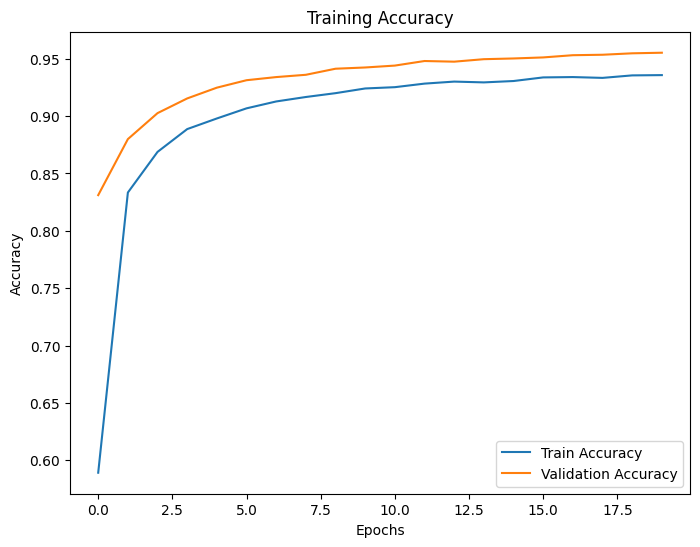

In [ ]:

train_loss, train_acc, train_f1 = model.evaluate(train_ds)
val_loss, val_acc, val_f1 = model.evaluate(val_ds)

print(f"Train Accuracy: {train_acc:.4f}, F1 Score: {train_f1:.4f}")
print(f"Val Accuracy: {val_acc:.4f}, F1 Score: {val_f1:.4f}")


plt.figure(figsize=(8,6))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [ ]:

model.save("plant_disease_efficientnet.keras")


In [ ]:


y_true = []
y_pred_prob = []

for images, labels in val_ds:
    preds = model.predict(images) 
    y_pred_prob.append(preds)
    y_true.append(labels.numpy())

y_true = np.concatenate(y_true)
y_pred_prob = np.concatenate(y_pred_prob)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true_classes = np.argmax(y_true, axis=1)

print("Shape of predictions:", y_pred_prob.shape)
print("Shape of true labels:", y_true.shape)


Shape of predictions: (17572, 38)
Shape of true labels: (17572, 38)


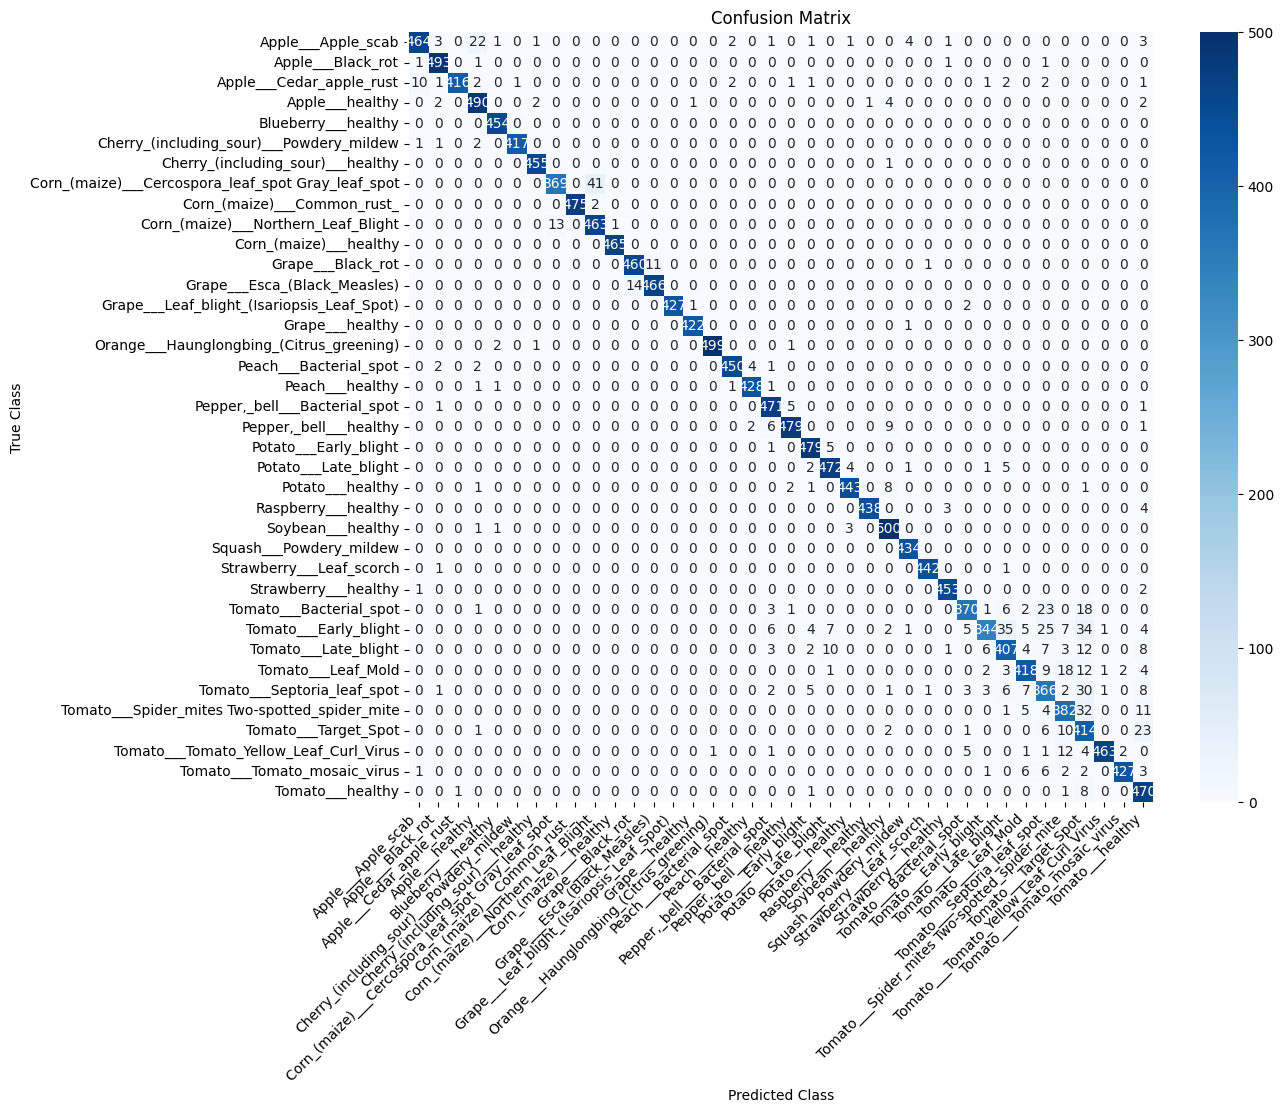

In [ ]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true_classes, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()


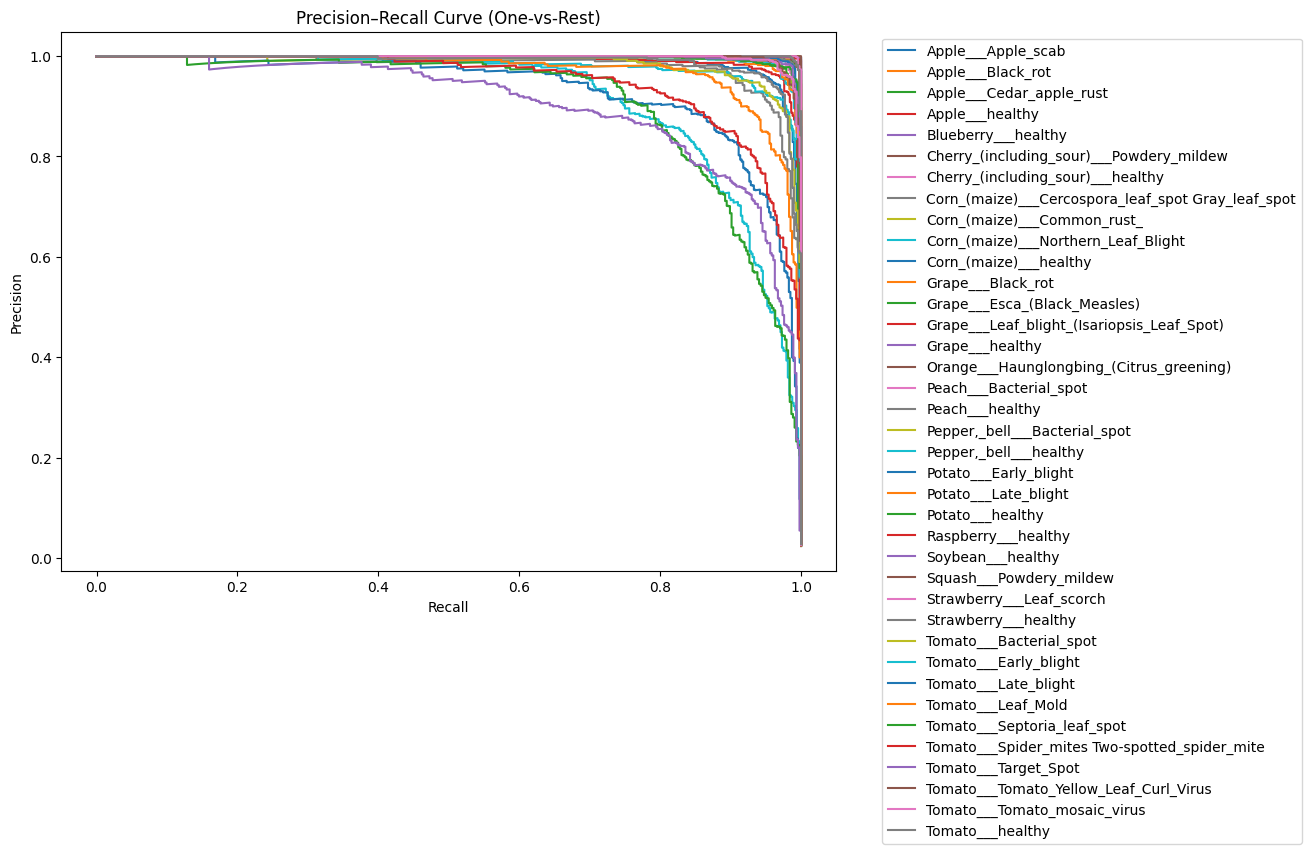

In [ ]:

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for i in range(NUM_CLASSES):
    precision, recall, _ = precision_recall_curve(
        y_true[:, i],
        y_pred_prob[:, i]
    )
    plt.plot(recall, precision, label=class_names[i])

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve (One-vs-Rest)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # labels outside
plt.show()


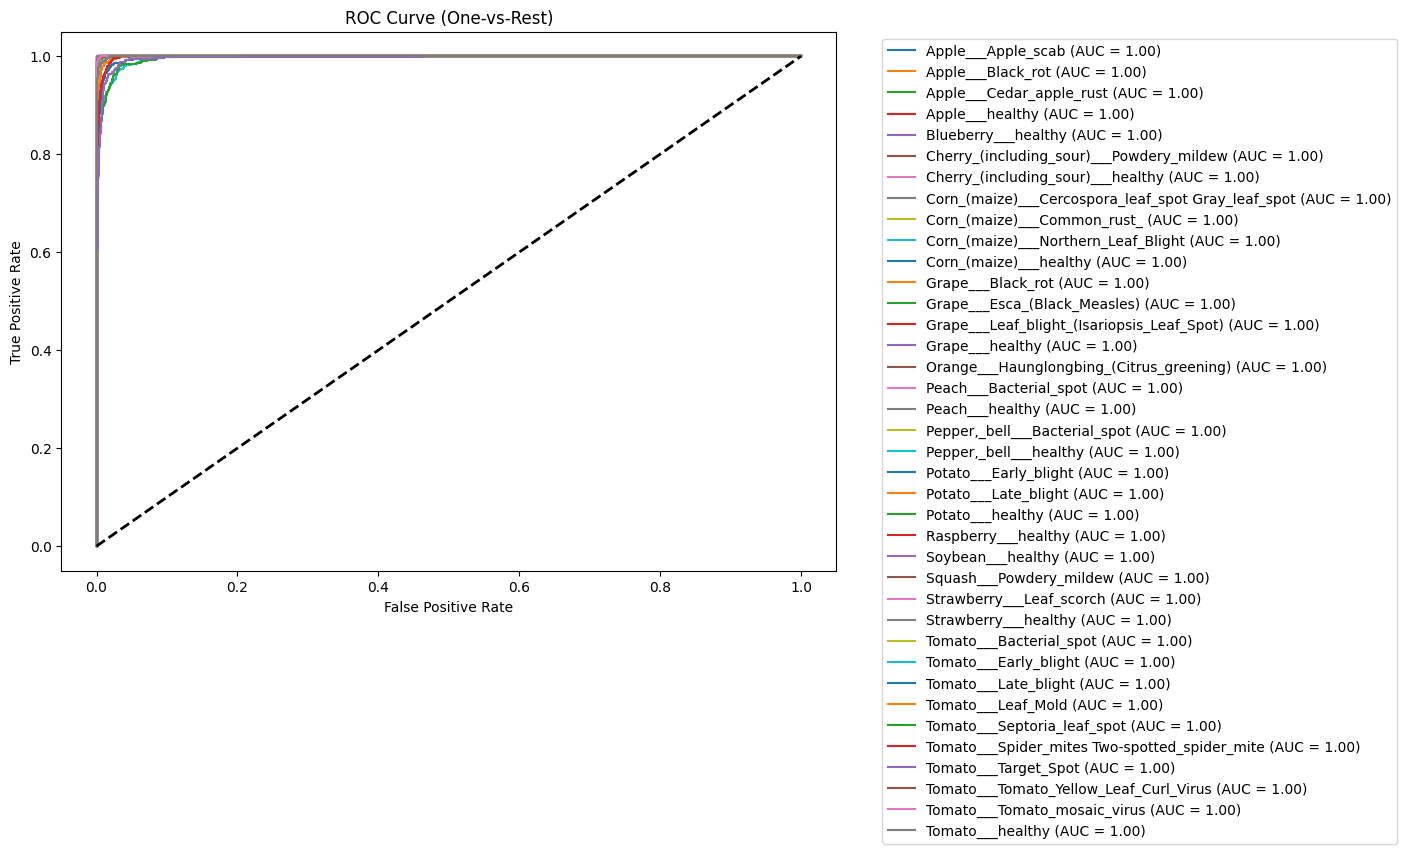

In [ ]:

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_true[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (One-vs-Rest)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()
